# 03.2 – MNIST

Reconnaissance de chiffres manuscrits : MLP, analyse des erreurs, expériences et CNN.

## 1. Données

In [2]:
import torch, torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

tf = transforms.ToTensor()
train = datasets.MNIST("data", train=True, download=True, transform=tf)
test = datasets.MNIST("data", train=False, transform=tf)
train_dl = DataLoader(train, batch_size=64, shuffle=True)
test_dl = DataLoader(test, batch_size=256)

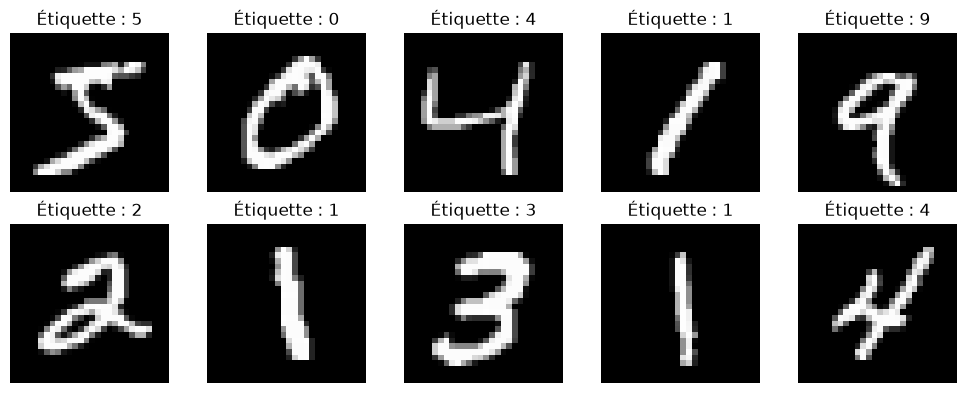

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    image, label = train[i]
    ax.imshow(image.squeeze(), cmap="gray")  # [1, 28, 28] -> [28, 28]
    ax.set_title(f"Étiquette : {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. Modèle (MLP)

In [4]:
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

## 3. Entraînement

In [5]:
for epoch in range(5):
    model.train()
    total_loss = 0
    for x, y in train_dl:
        opt.zero_grad()              # remet les gradients à zéro
        loss = loss_fn(model(x), y)  # calcul de la perte
        loss.backward()              # rétropropagation
        opt.step()                   # mise à jour des poids
        total_loss += loss.item() * x.size(0)
    print(f"Epoch {epoch + 1}/5 - perte moyenne : {total_loss / len(train):.4f}")

Epoch 1/5 - perte moyenne : 0.3383
Epoch 2/5 - perte moyenne : 0.1496
Epoch 3/5 - perte moyenne : 0.1058
Epoch 4/5 - perte moyenne : 0.0817
Epoch 5/5 - perte moyenne : 0.0652


## 4. Évaluation

In [6]:
def evaluate(model, dl):
    model.eval()                     # mode évaluation
    correct = 0
    with torch.no_grad():            # pas de calcul de gradients
        for x, y in dl:
            preds = model(x).argmax(dim=1)   # classe avec le score le plus élevé
            correct += (preds == y).sum().item()
    return correct / len(dl.dataset)


print(f"Précision sur le jeu de test : {evaluate(model, test_dl):.2%}")

Précision sur le jeu de test : 97.45%


## 5. Analyse des erreurs

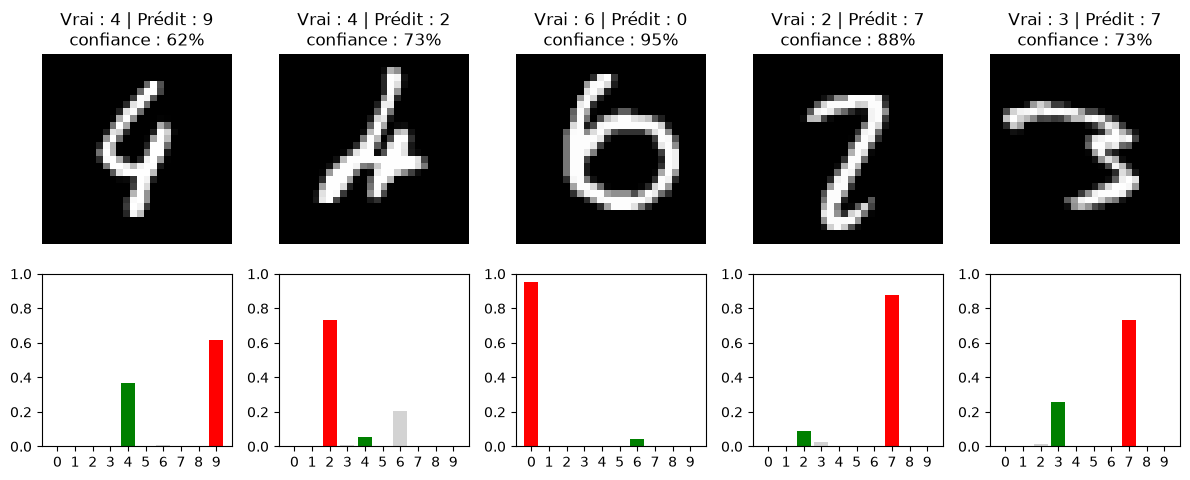

In [7]:
model.eval()
errors = []  # (image, vraie étiquette, prédiction, probabilités)
with torch.no_grad():
    for x, y in test_dl:
        probs = model(x).softmax(dim=1)   # scores -> probabilités
        preds = probs.argmax(dim=1)
        for i in (preds != y).nonzero().flatten():
            errors.append((x[i], y[i].item(), preds[i].item(), probs[i]))
        if len(errors) >= 5:
            break

fig, axes = plt.subplots(2, 5, figsize=(12, 5), gridspec_kw={"height_ratios": [3, 2]})
for k, (image, vrai, pred, p) in enumerate(errors[:5]):
    axes[0, k].imshow(image.squeeze(), cmap="gray")
    axes[0, k].set_title(f"Vrai : {vrai} | Prédit : {pred}\nconfiance : {p[pred]:.0%}")
    axes[0, k].axis("off")
    # probabilités du modèle pour chaque chiffre : vrai en vert, prédit en rouge
    colors = ["lightgray"] * 10
    colors[vrai], colors[pred] = "green", "red"
    axes[1, k].bar(range(10), p.numpy(), color=colors)
    axes[1, k].set_xticks(range(10))
    axes[1, k].set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 6. Expériences

### Taille de la couche cachée

In [8]:
# Expérience 1 : taille de la couche cachée (32, 128, 512)
def train_and_eval(model, epochs=5):
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(epochs):
        model.train()
        for x, y in train_dl:
            opt.zero_grad()
            loss_fn(model(x), y).backward()
            opt.step()
    return evaluate(model, test_dl)


for hidden in [32, 128, 512]:
    torch.manual_seed(0)  # même initialisation de départ pour comparer équitablement
    m = nn.Sequential(nn.Flatten(), nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 10))
    n_params = sum(p.numel() for p in m.parameters())
    acc = train_and_eval(m)
    print(f"Couche cachée : {hidden:>3} neurones | {n_params:>7} paramètres | précision test : {acc:.2%}")

Couche cachée :  32 neurones |   25450 paramètres | précision test : 95.68%
Couche cachée : 128 neurones |  101770 paramètres | précision test : 97.32%
Couche cachée : 512 neurones |  407050 paramètres | précision test : 97.95%


### Deuxième couche cachée

In [9]:
# Expérience 2 : ajout d'une 2ᵉ couche cachée
torch.manual_seed(0)
model_2 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),   # 2ᵉ couche cachée
    nn.Linear(64, 10),
)
n_params = sum(p.numel() for p in model_2.parameters())
acc = train_and_eval(model_2)
print(f"2 couches cachées (128 -> 64) | {n_params:>7} paramètres | précision test : {acc:.2%}")

2 couches cachées (128 -> 64) |  109386 paramètres | précision test : 97.56%


## 7. Défi : réseau convolutif (CNN)

In [10]:
# Défi : remplacer le MLP par un petit CNN (objectif : > 98,5 %)
torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),   # [1, 28, 28] -> [16, 28, 28]
    nn.MaxPool2d(2),                                         # -> [16, 14, 14]
    nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),  # -> [32, 14, 14]
    nn.MaxPool2d(2),                                         # -> [32, 7, 7]
    nn.Flatten(),                                            # -> 1568
    nn.Linear(32 * 7 * 7, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
n_params = sum(p.numel() for p in cnn.parameters())
acc = train_and_eval(cnn)
print(f"CNN | {n_params:>7} paramètres | précision test : {acc:.2%}")
print("Objectif atteint !" if acc > 0.985 else "Objectif non atteint, essayez plus d'epochs ou plus de filtres.")

CNN |  206922 paramètres | précision test : 98.81%
Objectif atteint !
